In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
font = {'size' : 15}
matplotlib.rc('font', **font)
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "Helvetica"
})
from skimage import measure
from scipy.spatial import ConvexHull
import os

In [2]:
source_folder = "interface_data/"
os.makedirs("plots", exist_ok=True)

In [3]:
fields = [0.13, 0.14, 0.15, 0.16]
fields_colors = matplotlib.colormaps.get('tab10')(range(4))

# Perimeter vs average radius, $P \\propto \\langle R \\rangle^{\\alpha}$
$P$ = length of the interface of NB3 (largest contour of inner domain + pixels switched up to $t$, sub-pixel, with overhangs),
$\\langle R \\rangle = \\langle R(\\theta,t) \\rangle_\\theta$ from the interfaces of NB3. Each field is fitted on its own.

### FUNCTIONS

In [4]:
def segment_noevents(data, no_event_val=-1):
    no_event_regions = [ r.astype('int') for r in measure.find_contours(data,no_event_val)]
    no_event_regions_sizes = np.array([r.shape[0] for r in no_event_regions])
    sorted_regions_idx = np.argsort(no_event_regions_sizes)
    inner_region = no_event_regions[sorted_regions_idx[-2]]
    outer_region = no_event_regions[sorted_regions_idx[-1]]
    center = inner_region.mean(axis=0)
    return inner_region,  outer_region, center

In [5]:
def get_inner_mask(data, inner_region):
    # same as NB3: mask of the inner (initial) domain from the convex hull of inner_region
    nrows, ncols = data.shape
    ii, jj = np.meshgrid(np.arange(0,nrows), np.arange(0,ncols), indexing='ij')
    pts = np.vstack([ii.flatten(), jj.flatten()])
    inner_hull = ConvexHull(inner_region)
    inner_mask = np.ones((nrows, ncols), dtype=bool)
    for eq in inner_hull.equations:
        eq_mask = np.dot(eq[:-1], pts) + eq[-1] <= 1e-12
        inner_mask[ii.flatten(),jj.flatten()] *= eq_mask
    return inner_mask

In [6]:
def perimeter_vs_time(data, inner_mask, t_list):
    # same contour as NB3, every frame in t_list; P = sum of the segment lengths
    temp_inner = np.zeros_like(data)
    temp_inner[inner_mask] = 1
    event_mask = data > - 1
    perimeter = []
    for t in t_list:
        temp = np.copy(temp_inner)
        temp[event_mask*(data<=t)] = 1
        regions = measure.find_contours(temp)
        r_sizes = [len(r) for r in regions]
        largest_r = regions[np.argmax(r_sizes)]
        perimeter.append(np.sqrt((np.diff(largest_r, axis=0)**2).sum(axis=1)).sum())
    return np.array(perimeter)

In [7]:
def fit_alpha(R, P, n_jack=5):
    # log-log slope, error from a jackknife over n_jack consecutive blocks (P(t) is correlated in time)
    alpha = np.polyfit(np.log(R), np.log(P), 1)
    blocks = np.array_split(np.arange(len(R)), n_jack)
    alpha_jack = np.array([ np.polyfit(np.log(np.delete(R, b)), np.log(np.delete(P, b)), 1)[0] for b in blocks])
    alpha_err = np.sqrt((n_jack-1)/n_jack*((alpha_jack-alpha_jack.mean())**2).sum())
    return alpha[0], alpha_err, alpha[1]

### EXECUTION

In [8]:
dt = 20
perimeter_dict = {}
for field in fields:
    print(field)
    data = np.loadtxt("data/file_field%1.2f.csv" % field, delimiter=',').astype('int')
    inner_region, outer_region, center = segment_noevents(data)
    inner_mask = get_inner_mask(data, inner_region)
    interface = np.load("%sinterface_field=%1.2f.npz" % (source_folder,field))['interface']
    t_list = np.arange(0, data.max()+1, dt)
    P = perimeter_vs_time(data, inner_mask, t_list)
    R_mean = interface[t_list, :-1].mean(axis=1)
    perimeter_dict[field] = (t_list, P, R_mean)

0.13


0.14


0.15


0.16


In [9]:
# fit away from the initial domain: <R> > 1.5 <R>(t=0)
R_min_factor = 1.5
alpha_dict = {}
for field in fields:
    t_list, P, R_mean = perimeter_dict[field]
    m = R_mean > R_min_factor*R_mean[0]
    alpha, alpha_err, b = fit_alpha(R_mean[m], P[m])
    alpha_dict[field] = (alpha, alpha_err, b)
    print("%1.2f  <R> = %i - %i px   alpha = %.3f +- %.3f   P/(2 pi <R>) at the end = %.2f" % (field, R_mean[m][0], R_mean[-1], alpha, alpha_err, P[-1]/(2*np.pi*R_mean[-1])))

0.13  <R> = 160 - 401 px   alpha = 1.085 +- 0.131   P/(2 pi <R>) at the end = 1.24
0.14  <R> = 119 - 419 px   alpha = 0.997 +- 0.017   P/(2 pi <R>) at the end = 1.11
0.15  <R> = 164 - 452 px   alpha = 1.010 +- 0.004   P/(2 pi <R>) at the end = 1.10
0.16  <R> = 103 - 448 px   alpha = 0.996 +- 0.002   P/(2 pi <R>) at the end = 1.08


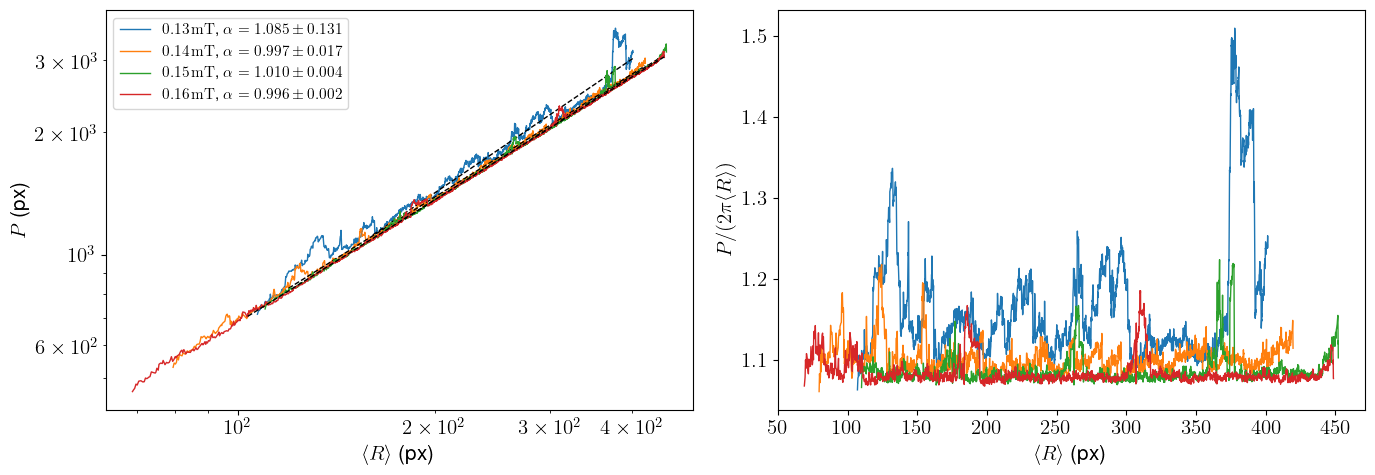

In [10]:
fig, ax = plt.subplots(figsize=(14,5), ncols=2)
for color, field in zip(fields_colors, fields):
    t_list, P, R_mean = perimeter_dict[field]
    alpha, alpha_err, b = alpha_dict[field]
    m = R_mean > R_min_factor*R_mean[0]
    ax[0].plot(R_mean, P, color=color, lw=1, label="$%1.2f \\, \\rm{mT}$, $\\alpha=%.3f \\pm %.3f$" % (field, alpha, alpha_err))
    ax[0].plot(R_mean[m], np.exp(b)*R_mean[m]**alpha, color='black', ls='dashed', lw=1)
    ax[1].plot(R_mean, P/(2*np.pi*R_mean), color=color, lw=1)
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].set_xlabel("$\\langle R \\rangle$ (px)")
ax[0].set_ylabel("$P$ (px)")
ax[0].legend(fontsize=11)
ax[1].set_xlabel("$\\langle R \\rangle$ (px)")
ax[1].set_ylabel("$P/(2\\pi \\langle R \\rangle)$")
plt.tight_layout()
plt.savefig("plots/perimeter_radius.pdf", bbox_inches='tight')
plt.show()